In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB, GaussianNB, BernoulliNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix, classification_report


In [3]:

def bayes(tien_nghiem, kha_nang, kha_nang_nguoc):
    """Trả về xác suất hậu nghiệm.
    
    tien_nghiem     : P(A), niềm tin trước khi có bằng chứng
    kha_nang        : P(B | A), bằng chứng xuất hiện khi A đúng
    kha_nang_nguoc  : P(B | không A), bằng chứng xuất hiện khi A sai
    """
    tu_so = kha_nang * tien_nghiem
    mau_so = tu_so + kha_nang_nguoc * (1 - tien_nghiem)
    return tu_so / mau_so


print("Vi du 1: xet nghiem benh")
print("  Ty le mac benh 1 phan tram, xet nghiem dung 99 phan tram.")
p = bayes(tien_nghiem=0.01, kha_nang=0.99, kha_nang_nguoc=0.01)
print(f"  Duong tinh thi kha nang co benh that = {p:.4f}")
print()

print("Cung xet nghiem do, doi ty le mac benh:")
print("  Ty le mac benh   Hau nghiem khi duong tinh")
for ty_le in [0.001, 0.01, 0.05, 0.10, 0.50]:
    print(f"  {ty_le:6.3f}           {bayes(ty_le, 0.99, 0.01):.4f}")
print()

print("Vi du 2: hai day chuyen san xuat")
print("  Day A lam 80 phan tram san pham, ty le loi 1 phan tram.")
print("  Day B lam 20 phan tram san pham, ty le loi 5 phan tram.")

p_b = bayes(tien_nghiem=0.20, kha_nang=0.05, kha_nang_nguoc=0.01)
print(f"  Nhat duoc san pham loi, kha nang no tu day B = {p_b:.4f}")
print()

print("Kiem lai bang cach dem tren 1000 san pham:")
loi_a = 800 * 0.01
loi_b = 200 * 0.05
print(f"  Day A: 800 san pham, {loi_a:.0f} cai loi")
print(f"  Day B: 200 san pham, {loi_b:.0f} cai loi")
tong_loi = loi_a + loi_b
print(f"  Ty le tu day B = {loi_b} / {tong_loi} = {loi_b / tong_loi:.4f}")


Vi du 1: xet nghiem benh
  Ty le mac benh 1 phan tram, xet nghiem dung 99 phan tram.
  Duong tinh thi kha nang co benh that = 0.5000

Cung xet nghiem do, doi ty le mac benh:
  Ty le mac benh   Hau nghiem khi duong tinh
   0.001           0.0902
   0.010           0.5000
   0.050           0.8390
   0.100           0.9167
   0.500           0.9900

Vi du 2: hai day chuyen san xuat
  Day A lam 80 phan tram san pham, ty le loi 1 phan tram.
  Day B lam 20 phan tram san pham, ty le loi 5 phan tram.
  Nhat duoc san pham loi, kha nang no tu day B = 0.5556

Kiem lai bang cach dem tren 1000 san pham:
  Day A: 800 san pham, 8 cai loi
  Day B: 200 san pham, 10 cai loi
  Ty le tu day B = 10.0 / 18.0 = 0.5556


> **Bài học mang sang phần sau:**  
> Xác suất tiên nghiệm $P(A)$ quan trọng ngang với bằng chứng. Trong bài toán phân loại, tiên nghiệm chính là tỷ lệ của từng lớp trong dữ liệu huấn luyện, và Naive Bayes luôn nhân nó vào. Đó là lý do một lớp hiếm rất khó được mô hình chọn.


---
# 3. Biến văn bản thành số

### 3.1. Bộ dữ liệu tin nhắn
- Tệp `data/tin_nhan.csv` có 300 dòng và 2 cột:
  - Cột `noi_dung`: Văn bản tin nhắn.
  - Cột `la_rac`: Nhãn phân loại ($1$ là tin rác, $0$ là tin thường).

### 3.2. Mô hình Túi từ (Bag of Words)
Máy không đọc được chữ, nên việc đầu tiên là đổi mỗi tin nhắn thành một dãy số. Cách đơn giản nhất là **túi từ**: lập từ điển gồm mọi từ xuất hiện trong tập dữ liệu, rồi mỗi tin nhắn biến thành một vector đếm số lần từng từ xuất hiện.

> **Túi từ bỏ mất thứ tự từ:**  
> Câu *"chó cắn người"* và câu *"người cắn chó"* cho ra cùng một túi từ. Với bài toán lọc tin rác, điều này chấp nhận được vì bản thân sự xuất hiện của các từ khóa nhạy cảm đã đủ để phân loại.


In [4]:

data_path = "data/tin_nhan.csv" if os.path.exists("data/tin_nhan.csv") else "Data/tin_nhan.csv"
df = pd.read_csv(data_path)

print("Kich thuoc bang:", df.shape)
print()
print("So tin theo nhan (1 la rac, 0 la thuong):")
print(df["la_rac"].value_counts())
print()
print("Ty le tin rac:", round(df["la_rac"].mean(), 4))
print()

print("Ba tin nhan dau tien:")
for i in range(3):
    print(f"  [{df.la_rac[i]}] {df.noi_dung[i]}")
print()


vec = CountVectorizer(token_pattern=r"(?u)\S+")
X = vec.fit_transform(df["noi_dung"])

print("Kich thuoc bang dem tu:", X.shape)
print("So tu trong tu dien:", len(vec.vocabulary_))
print()

dem = pd.DataFrame(X.toarray(), columns=vec.get_feature_names_out())
dem["la_rac"] = df["la_rac"]
tong = dem.groupby("la_rac").sum().T
tong.columns = ["thuong", "rac"]

print("Muoi tu xuat hien nhieu nhat trong tin rac:")
print(tong.sort_values("rac", ascending=False).head(10))
print()
print("Muoi tu xuat hien nhieu nhat trong tin thuong:")
print(tong.sort_values("thuong", ascending=False).head(10))


Kich thuoc bang: (300, 2)

So tin theo nhan (1 la rac, 0 la thuong):
la_rac
0    180
1    120
Name: count, dtype: int64

Ty le tin rac: 0.4

Ba tin nhan dau tien:
  [0] cáo gửi cáo thầy nhóm cáo gửi có cho
  [1] miễn giảm ngay hạn miễn tay nhé thưởng cho nhanh
  [0] cho bạn mai gửi nhóm bài chiều

Kich thuoc bang dem tu: (300, 40)
So tu trong tu dien: 40

Muoi tu xuat hien nhieu nhat trong tin rac:
       thuong  rac
tay         3   48
ngay        4   47
nhanh       9   44
chót        6   43
giảm        6   42
lúc        39   42
quà         8   41
phí         6   40
click       5   40
tặng        7   39

Muoi tu xuat hien nhieu nhat trong tin thuong:
       thuong  rac
thầy       74    7
bài        73    4
cáo        72    8
chiều      68    8
ạ          65    7
tài        64   11
tập        63    6
gửi        61   10
lớp        60    2
nhóm       58    7


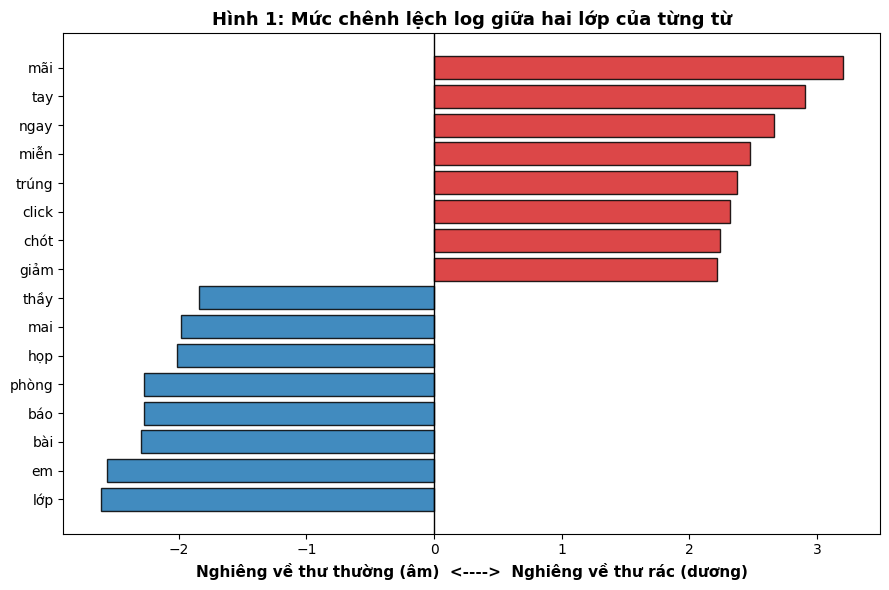

In [5]:

p_rac = (tong["rac"] + 1) / (tong["rac"].sum() + 40)
p_thuong = (tong["thuong"] + 1) / (tong["thuong"].sum() + 40)
log_diff = np.log(p_rac / p_thuong)

df_plot = pd.DataFrame({"tu": tong.index, "chenh_lech": log_diff}).sort_values("chenh_lech")


top_words = pd.concat([df_plot.head(8), df_plot.tail(8)])

plt.figure(figsize=(9, 6))
colors = ['#1f77b4' if v < 0 else '#d62728' for v in top_words['chenh_lech']]
plt.barh(top_words['tu'], top_words['chenh_lech'], color=colors, edgecolor='black', alpha=0.85)
plt.axvline(0, color='black', linewidth=1)
plt.xlabel("Nghiêng về thư thường (âm)  <---->  Nghiêng về thư rác (dương)", fontsize=11, fontweight='bold')
plt.title("Hình 1: Mức chênh lệch log giữa hai lớp của từng từ", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


---
# 4. Bộ lọc tin nhắn rác

### 4.1. Công thức Naive Bayes
Với một tin nhắn gồm các từ $x_1, \dots, x_d$, quy tắc quyết định là:
$$\hat{y} = \arg\max_k P(y = k) \prod_{j=1}^d P(x_j \mid y = k)$$

- **Mẫu số $P(B)$ đã được bỏ đi** vì giống hệt nhau ở mọi lớp.
- **Giả định ngây thơ (Naive assumption):** Khi biết lớp, sự xuất hiện của các từ là độc lập với nhau.
- **Huấn luyện chỉ là đếm tần suất:**
$$P(\text{từ } j \mid \text{lớp } k) = \frac{\text{số lần từ } j \text{ xuất hiện trong lớp } k}{\text{tổng số từ của lớp } k}$$
Không cần tối ưu lặp vòng (*gradient descent*) như Logistic Regression, máy chỉ cần duyệt dữ liệu đúng một lượt.


In [6]:

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)
print("So tin de hoc     :", X_train.shape[0])
print("So tin de kiem tra:", X_test.shape[0])
print()

mo_hinh = MultinomialNB(alpha=1.0)
mo_hinh.fit(X_train, y_train)
y_pred = mo_hinh.predict(X_test)

tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
print("Ma tran nham lan")
print(f"  TN = {tn:2d}   thu thuong duoc giu dung")
print(f"  FP = {fp:2d}   thu thuong bi xoa nham")
print(f"  FN = {fn:2d}   thu rac lot luoi")
print(f"  TP = {tp:2d}   thu rac bi chan dung")
print()

print(f"Accuracy  = {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision = {precision_score(y_test, y_pred):.4f}")
print(f"Recall    = {recall_score(y_test, y_pred):.4f}")
print()


tin_moi = [
    "trung thuong khuyen mai nhanh tay click ngay",
    "hop nhom bao cao chieu mai phong 305",
    "ban gui giup em tai lieu bai tap nhe",
]
X_moi = vec.transform(tin_moi)
p_rac = mo_hinh.predict_proba(X_moi)[:, 1]

print("Thu tren ba tin nhan tu go:")
for tin, p in zip(tin_moi, p_rac):
    nhan = "RAC" if p >= 0.5 else "thuong"
    print(f"  [{nhan:6s}] p = {p:.4f}  <- {tin}")


NameError: name 'y' is not defined

In [ ]:

cm_data = np.array([[tn, fp], [fn, tp]])
plt.figure(figsize=(5, 4))
sns.heatmap(cm_data, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Đoán thường', 'Đoán rác'],
            yticklabels=['Thật: thường', 'Thật: rác'],
            annot_kws={'size': 14, 'weight': 'bold'})
plt.title("Hình 2: Ma trận nhầm lẫn của bộ lọc (75 tin test)", fontsize=12, fontweight='bold')
plt.show()


NameError: name 'tn' is not defined

### 4.3. Đọc kết quả & Phân tích
- **Accuracy đạt 0.9467 (94.67%)**.
- **Precision = 1.0000 (100%):** Trong tất cả tin bị gán nhãn rác, không có tin nào là thư thật ($FP = 0$).
- **Recall = 0.8667 (86.67%):** Bắt được $26/30$ tin rác, để lọt $4$ tin ($FN = 4$).

> **Vì sao kết quả này đáng mừng?**  
> Trong bài toán lọc thư rác:  
> - Sai kiểu $FP$: Xoá nhầm một lá thư thật quan trọng $\rightarrow$ Hậu quả rất nặng!  
> - Sai kiểu $FN$: Để lọt một tin rác vào hộp thư đến $\rightarrow$ Người dùng tự xóa tay, hậu quả nhẹ.  
> Bộ lọc này để lọt 4 tin rác nhưng **không xóa nhầm bức thư thật nào ($FP=0$)**. Đó đúng là kiểu sai rẻ tiền mà ta mong muốn.

> **Xác suất của Naive Bayes thường quá tự tin:**  
> Do giả định ngây thơ, mô hình đếm cùng một bằng chứng nhiều lần khi các từ đi kèm nhau, đẩy xác suất về sát $0$ hoặc $1$ ($0.9992$, $0.0719$). Dùng nó để phân lớp thì rất tốt, nhưng không nên xem đây là độ tin cậy tuyệt đối ngoài đời thực.


---
# 5. Vấn đề số không và cách làm trơn

### 5.1. Một số không đủ sức khoá cả phép nhân
Trong công thức Naive Bayes, nếu một từ **chưa từng xuất hiện** trong một lớp ở tập huấn luyện, thì xác suất của từ đó trong lớp bằng $0$.  
Khi đem nhân vào tích, toàn bộ xác suất của lớp đó lập tức trở thành $0$, bất chấp tất cả các từ còn lại mang dấu hiệu mạnh mẽ đến đâu!

### 5.2. Làm trơn Laplace (Laplace Smoothing)
Cộng thêm một lượng nhỏ $\alpha$ vào số đếm:
$$P(\text{từ } j \mid \text{lớp } k) = \frac{\text{đếm}_{jk} + \alpha}{\text{tổng}_k + \alpha V}$$
- $V$: Tổng số từ trong từ điển.
- $\alpha$: Hệ số làm trơn (thường chọn $\alpha = 1$).


In [ ]:

kho = [
    ("trung thuong ngay", 1),
    ("khuyen mai giam gia", 1),
    ("trung thuong click", 1),
    ("hop nhom chieu mai", 0),
    ("bai tap nhom nop mai", 0),
    ("thay gui tai lieu", 0),
]

tu_dien = sorted({t for cau, _ in kho for t in cau.split()})
V = len(tu_dien)
print(f"Tu dien co {V} tu:")
for i in range(0, V, 9):
    print("  " + " ".join(tu_dien[i:i + 9]))
print()


dem = {0: Counter(), 1: Counter()}
tong = {0: 0, 1: 0}
for cau, nhan in kho:
    for t in cau.split():
        dem[nhan][t] += 1
        tong[nhan] += 1

print("So lan xuat hien cua tung tu:")
print(f"  {'tu':12s} {'rac':>5s} {'thuong':>7s}")
for t in tu_dien:
    print(f"  {t:12s} {dem[1][t]:5d} {dem[0][t]:7d}")
print()

def xac_suat(tu, nhan, alpha):
    """P(tu | nhan) co lam tron Laplace voi he so alpha."""
    return (dem[nhan][tu] + alpha) / (tong[nhan] + alpha * V)

def diem(cau, nhan, alpha):
    """Tich cua xac suat tien nghiem va cac xac suat tu."""
    p = 0.5  
    for t in cau.split():
        if t in tu_dien:
            p *= xac_suat(t, nhan, alpha)
    return p

cau_thu = "trung thuong bai tap"
print(f'Tin nhan thu: "{cau_thu}"')
print("Tu 'bai' chi xuat hien o lop thuong, chua bao gio o lop rac.")
print()

for alpha in [0.0, 1.0]:
    d_rac = diem(cau_thu, 1, alpha)
    d_thuong = diem(cau_thu, 0, alpha)
    ket = "rac" if d_rac > d_thuong else "thuong"
    print(f"alpha = {alpha}")
    print(f"  diem lop rac    = {d_rac:.10f}")
    print(f"  diem lop thuong = {d_thuong:.10f}")
    print(f"  ket luan        = {ket}")
    print()

print("Khong lam tron, CA HAI diem deu bang 0 nen mo hinh te liet.")
print("Lop rac bang 0 vi tu 'bai' chua tung xuat hien o lop rac.")
print("Lop thuong bang 0 vi tu 'trung' chua tung xuat hien o lop thuong.")
print("Co lam tron, diem lop rac lon hon va mo hinh ket luan dung.")


Tu dien co 18 tu:
  bai chieu click gia giam gui hop khuyen lieu
  mai ngay nhom nop tai tap thay thuong trung

So lan xuat hien cua tung tu:
  tu             rac  thuong
  bai              0       1
  chieu            0       1
  click            1       0
  gia              1       0
  giam             1       0
  gui              0       1
  hop              0       1
  khuyen           1       0
  lieu             0       1
  mai              1       2
  ngay             1       0
  nhom             0       2
  nop              0       1
  tai              0       1
  tap              0       1
  thay             0       1
  thuong           2       0
  trung            2       0

Tin nhan thu: "trung thuong bai tap"
Tu 'bai' chi xuat hien o lop thuong, chua bao gio o lop rac.

alpha = 0.0
  diem lop rac    = 0.0000000000
  diem lop thuong = 0.0000000000
  ket luan        = thuong

alpha = 1.0
  diem lop rac    = 0.0000073212
  diem lop thuong = 0.0000021656
  ket luan        = rac

In [ ]:

alpha_vals = np.linspace(0.0, 2.0, 100)

prob_bai_rac = [(0 + a) / (tong[1] + a * V) for a in alpha_vals]

plt.figure(figsize=(7, 4))
plt.plot(alpha_vals, prob_bai_rac, color='#1f77b4', linewidth=2.5, label='P("bài" | thư rác)')
plt.scatter([0], [0], color='red', s=80, zorder=5)
plt.annotate('alpha = 0 cho xác suất đúng bằng 0', xy=(0, 0), xytext=(0.4, 0.005),
             arrowprops=dict(arrowstyle='->', color='red', lw=1.5), color='red', fontweight='bold')
plt.xlabel("Tham số làm trơn alpha", fontsize=11)
plt.ylabel('P("bài" | thư rác)', fontsize=11)
plt.title("Hình 3: Làm trơn kéo xác suất của từ chưa gặp ra khỏi số 0", fontsize=12, fontweight='bold')
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend()
plt.tight_layout()
plt.show()


### Hiện tượng tràn dưới (Underflow) và cách giải quyết bằng hàm Log:
Khi tin nhắn dài, nhân nhiều xác suất nhỏ (vài %) với nhau sẽ khiến tích số tiến dần về $0$ vượt quá độ chính xác dấu phẩy động của máy tính (`float64`).  
**Cách chữa:** Chuyển sang thang $\log$:
$$\log \left( P(y) \prod_{j} P(x_j \mid y) \right) = \log P(y) + \sum_{j} \log P(x_j \mid y)$$
Vì hàm $\log$ đồng biến, thứ tự so sánh giữa các lớp hoàn toàn không thay đổi!  
Scikit-learn lưu trữ các giá trị này trong thuộc tính `feature_log_prob_`.


---
# 6. Naive Bayes cho số liệu liên tục

### 6.1. Đếm không còn dùng được
Với các biến số thực như `gio_on` (số giờ ôn tập) hay `diem_giua_ky`, không ai đếm được số lần xuất hiện của một giá trị cụ thể như $12.5$.  
Giải pháp là giả định mỗi lớp tuân theo một **phân phối chuẩn (Gaussian)**:
$$P(x_i \mid y = k) = \frac{1}{\sqrt{2\pi \sigma_{ik}^2}} \exp\left( -\frac{(x_i - \mu_{ik})^2}{2\sigma_{ik}^2} \right)$$

Huấn luyện mô hình chỉ đơn giản là tính:
- Trung bình $\mu_{ik}$ (lưu trong `gnb.theta_`)
- Phương sai $\sigma_{ik}^2$ (lưu trong `gnb.var_`)


In [ ]:


data_path_sv = "data/sinh_vien.csv" if os.path.exists("data/sinh_vien.csv") else "Data/sinh_vien.csv"
df_sv = pd.read_csv(data_path_sv)
X_sv = df_sv[["gio_on", "diem_giua_ky"]]
y_sv = df_sv["qua_mon"]

X_tr_sv, X_te_sv, y_tr_sv, y_te_sv = train_test_split(
    X_sv, y_sv, test_size=0.25, random_state=17, stratify=y_sv
)

for ten, mo_hinh in [("Naive Bayes    ", GaussianNB()),
                     ("Hoi quy logistic", LogisticRegression())]:
    mo_hinh.fit(X_tr_sv, y_tr_sv)
    acc = accuracy_score(y_te_sv, mo_hinh.predict(X_te_sv))
    print(f"{ten}: accuracy = {acc:.4f}")
print()

gnb = GaussianNB().fit(X_tr_sv, y_tr_sv)


print("Nhung gi Naive Bayes hoc duoc:")
print(f"  {'':16s} {'gio_on':>10s} {'diem_giua_ky':>14s}")
for i, ten_lop in enumerate(["Lop 0 (rot) ", "Lop 1 (qua) "]):
    tb = gnb.theta_[i]
    dl = gnb.var_[i] ** 0.5
    print(f"  {ten_lop} trung binh {tb[0]:10.2f} {tb[1]:14.2f}")
    print(f"  {'':12s} do lech    {dl[0]:10.2f} {dl[1]:14.2f}")
print()

ty_le = ", ".join(f"{float(v):.4f}" for v in gnb.class_prior_)
print(f"Ty le tung lop trong tap hoc: {ty_le}")
print()


ban_moi = pd.DataFrame({"gio_on": [5, 13, 20, 28],
                        "diem_giua_ky": [4.0, 6.0, 7.0, 9.0]})
p = gnb.predict_proba(ban_moi)[:, 1]
print("Du doan cho bon ban moi:")
print(f"  {'gio on':>8s} {'diem GK':>9s} {'P(qua mon)':>12s}")
for (_, r), pi in zip(ban_moi.iterrows(), p):
    print(f"  {r.gio_on:8.0f} {r.diem_giua_ky:9.1f} {pi:12.4f}")


Naive Bayes    : accuracy = 0.9000
Hoi quy logistic: accuracy = 0.9000

Nhung gi Naive Bayes hoc duoc:
                   gio_on   diem_giua_ky
  Lop 0 (rot)  trung binh       8.18           3.99
               do lech          5.29           1.92
  Lop 1 (qua)  trung binh      20.03           6.70
               do lech          5.81           1.50

Ty le tung lop trong tap hoc: 0.4111, 0.5889

Du doan cho bon ban moi:
    gio on   diem GK   P(qua mon)
         5       4.0       0.0137
        13       6.0       0.6550
        20       7.0       0.9855
        28       9.0       0.9999


In [ ]:

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

x_min, x_max = X_sv['gio_on'].min() - 2, X_sv['gio_on'].max() + 2
y_min, y_max = X_sv['diem_giua_ky'].min() - 1, X_sv['diem_giua_ky'].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200), np.linspace(y_min, y_max, 200))
grid_points = np.c_[xx.ravel(), yy.ravel()]

models = [
    ("Hồi quy logistic", LogisticRegression().fit(X_tr_sv, y_tr_sv)),
    ("Naive Bayes", GaussianNB().fit(X_tr_sv, y_tr_sv))
]

for ax, (name, clf) in zip(axes, models):
    Z = clf.predict(grid_points).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.25, cmap=plt.cm.coolwarm)
    ax.scatter(df_sv[df_sv['qua_mon']==0]['gio_on'], df_sv[df_sv['qua_mon']==0]['diem_giua_ky'],
               c='crimson', marker='o', edgecolors='k', label='Rớt (0)')
    ax.scatter(df_sv[df_sv['qua_mon']==1]['gio_on'], df_sv[df_sv['qua_mon']==1]['diem_giua_ky'],
               c='royalblue', marker='s', edgecolors='k', label='Qua (1)')
    ax.set_title(name, fontsize=12, fontweight='bold')
    ax.set_xlabel("Số giờ ôn tập", fontsize=11)
    ax.set_ylabel("Điểm giữa kỳ", fontsize=11)
    ax.legend(loc='lower right')

plt.suptitle("Hình 5: Biên quyết định của hai mô hình trên cùng bộ dữ liệu", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


### Điểm khác nhau cốt lõi giữa Naive Bayes và Logistic Regression:
| Tình huống | Naive Bayes | Hồi quy Logistic |
| :--- | :--- | :--- |
| **Bản chất mô hình** | **Generative model:** Học hình dạng từng lớp $P(x \mid y)$ rồi suy ra biên. | **Discriminative model:** Học trực tiếp ranh giới quyết định $P(y \mid x)$. |
| **Dữ liệu ít, đặc trưng nhiều** | **Rất hợp** (ước lượng từng đặc trưng độc lập). | Dễ bị quá khớp (*overfitting*). |
| **Dữ liệu nhiều** | Thường thua một chút vì giả định ngây thơ. | **Nhỉnh hơn**, linh hoạt hơn. |
| **Tốc độ huấn luyện** | **Cực nhanh** (chỉ đếm và tính trung bình 1 lượt). | Phải lặp dò tìm nghiệm tối ưu qua gradient. |
| **Độ tin cậy xác suất** | Xác suất thường bị thổi phồng sát 0 hoặc 1. | **Đáng tin cậy hơn**, dùng tốt để chọn ngưỡng. |


---
# 7. HƯỚNG DẪN VÀ LỜI GIẢI CHI TIẾT 6 BÀI TẬP (MỤC 7)

Phần này thực hiện giải toàn bộ 6 bài tập lớn trong giáo trình theo đúng hướng dẫn, in kết quả đầy đủ và nhận xét bản chất lý thuyết.


## Bài tập 1: Bayes với ba nguyên nhân
> **Đề bài:** Một lớp có ba nhóm sinh viên: $50\%$ học đều, $30\%$ học dồn, $20\%$ ít học. Tỷ lệ qua môn của ba nhóm lần lượt là $0.95$, $0.70$ và $0.30$.  
> Gặp một bạn đã qua môn. Tính xác suất bạn đó thuộc từng nhóm. Ba con số cộng lại phải bằng 1, hãy dùng điều đó để tự kiểm tra.  
> *Gợi ý:* Mở rộng hàm `bayes` trong `d1_bayes_tay.py` cho ba nhánh thay vì hai.


In [ ]:

def bayes_n_nhanh(tien_nghiem, kha_nang):
    """Tính xác suất hậu nghiệm cho n nhóm nguyên nhân.
    
    tien_nghiem : danh sách P(A_i)
    kha_nang    : danh sách P(B | A_i)
    """
    tu_so = [p_kn * p_tn for p_kn, p_tn in zip(kha_nang, tien_nghiem)]
    mau_so = sum(tu_so)  
    hau_nghiem = [ts / mau_so for ts in tu_so]
    return hau_nghiem, mau_so

ten_nhom = ["Học đều", "Học dồn", "Ít học"]
tien_nghiem = [0.50, 0.30, 0.20]
kha_nang_qua = [0.95, 0.70, 0.30]

hau_nghiem, p_qua = bayes_n_nhanh(tien_nghiem, kha_nang_qua)

print("=" * 60)
print("BÀI TẬP 1: BAYES VỚI BA NGUYÊN NHÂN")
print("=" * 60)
print(f"Xác suất một sinh viên bất kỳ qua môn P(Qua): {p_qua:.4f}")
print("Xác suất sinh viên đó thuộc từng nhóm khi biết bạn đó ĐÃ QUA MÔN:")
for ten, p in zip(ten_nhom, hau_nghiem):
    print(f"  P({ten:8s} | qua môn) = {p:.4f} ({p*100:.2f}%)")

tong_p = sum(hau_nghiem)
print(f"\nTổng các xác suất hậu nghiệm: {tong_p:.4f}")
assert abs(tong_p - 1.0) < 1e-6, "Tổng xác suất phải bằng 1!"
print("=> KẾT QUẢ: Tổng xác suất bằng đúng 1.0, đáp án chính xác hoàn toàn.")


BÀI TẬP 1: BAYES VỚI BA NGUYÊN NHÂN
Xác suất một sinh viên bất kỳ qua môn P(Qua): 0.7450
Xác suất sinh viên đó thuộc từng nhóm khi biết bạn đó ĐÃ QUA MÔN:
  P(Học đều  | qua môn) = 0.6376 (63.76%)
  P(Học dồn  | qua môn) = 0.2819 (28.19%)
  P(Ít học   | qua môn) = 0.0805 (8.05%)

Tổng các xác suất hậu nghiệm: 1.0000
=> KẾT QUẢ: Tổng xác suất bằng đúng 1.0, đáp án chính xác hoàn toàn.


---
## Bài tập 2: Từ nào tố cáo mạnh nhất
> **Đề bài:** Huấn luyện `MultinomialNB` trên toàn bộ 300 tin nhắn. Dùng thuộc tính `feature_log_prob_` để tính hiệu giữa hai lớp cho từng từ, rồi in ra 5 từ tố cáo tin rác mạnh nhất và 5 từ cho thấy tin thường mạnh nhất.  
> *Gợi ý:* `feature_log_prob_` là một mảng hai dòng, dòng 0 cho lớp 0 và dòng 1 cho lớp 1. Lấy `mo_hinh.feature_log_prob_[1] - mo_hinh.feature_log_prob_[0]` rồi sắp xếp.


In [ ]:

vec_all = CountVectorizer(token_pattern=r"(?u)\S+")
X_all = vec_all.fit_transform(df["noi_dung"])
y_all = df["la_rac"]

mo_hinh_all = MultinomialNB()
mo_hinh_all.fit(X_all, y_all)

tu_vung = vec_all.get_feature_names_out()

hieu_so = mo_hinh_all.feature_log_prob_[1] - mo_hinh_all.feature_log_prob_[0]

df_hieu = pd.DataFrame({
    "Từ": tu_vung,
    "log_prob_rác": mo_hinh_all.feature_log_prob_[1],
    "log_prob_thường": mo_hinh_all.feature_log_prob_[0],
    "Chênh lệch (Rác - Thường)": hieu_so
})

print("=" * 60)
print("BÀI TẬP 2: TỪ NÀO TỐ CÁO MẠNH NHẤT")
print("=" * 60)

print("\n>>> TOP 5 TỪ TỐ CÁO TIN RÁC MẠNH NHẤT (Chênh lệch dương cao nhất):")
top_rac = df_hieu.sort_values("Chênh lệch (Rác - Thường)", ascending=False).head(5)
print(top_rac[["Từ", "Chênh lệch (Rác - Thường)"]].to_string(index=False))

print("\n>>> TOP 5 TỪ CHO THẤY TIN THƯỜNG MẠNH NHẤT (Chênh lệch âm thấp nhất):")
top_thuong = df_hieu.sort_values("Chênh lệch (Rác - Thường)", ascending=True).head(5)
print(top_thuong[["Từ", "Chênh lệch (Rác - Thường)"]].to_string(index=False))


BÀI TẬP 2: TỪ NÀO TỐ CÁO MẠNH NHẤT

>>> TOP 5 TỪ TỐ CÁO TIN RÁC MẠNH NHẤT (Chênh lệch dương cao nhất):
   Từ  Chênh lệch (Rác - Thường)
  mãi                   3.203435
  tay                   2.905600
 ngay                   2.661837
 miễn                   2.479516
trúng                   2.374155

>>> TOP 5 TỪ CHO THẤY TIN THƯỜNG MẠNH NHẤT (Chênh lệch âm thấp nhất):
   Từ  Chênh lệch (Rác - Thường)
  lớp                  -2.612187
   em                  -2.561756
  bài                  -2.294553
  báo                  -2.274074
phòng                  -2.274074


---
## Bài tập 3: Đổi tham số làm trơn
> **Đề bài:** Chạy lại bộ lọc với alpha lần lượt bằng $0.001, 0.1, 1.0, 10.0$ và $100.0$. Với mỗi giá trị, in ra accuracy, precision và recall trên tập kiểm tra.  
> Nhận xét một câu: alpha lớn quá thì chuyện gì xảy ra, và vì sao?  
> *(Gợi ý: alpha rất lớn làm mọi xác suất từ xích lại gần nhau).*


In [ ]:
alphas = [0.001, 0.1, 1.0, 10.0, 100.0]
ket_qua = []

print("=" * 60)
print("BÀI TẬP 3: THỬ NGHIỆM THAM SỐ LÀM TRƠN ALPHA")
print("=" * 60)
print(f"{'alpha':>10s} | {'Accuracy':>10s} | {'Precision':>10s} | {'Recall':>10s}")
print("-" * 50)

for a in alphas:
    clf = MultinomialNB(alpha=a).fit(X_train, y_train)
    y_pred = clf.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    ket_qua.append({"alpha": a, "Accuracy": acc, "Precision": prec, "Recall": rec})
    print(f"{a:10.3f} | {acc:10.4f} | {prec:10.4f} | {rec:10.4f}")

# Thử nghiệm thêm giá trị alpha cực lớn để thấy rõ hiện tượng
clf_extreme = MultinomialNB(alpha=10000.0).fit(X_train, y_train)
y_pred_extreme = clf_extreme.predict(X_test)
print(f"{10000.0:10.1f} | {accuracy_score(y_test, y_pred_extreme):10.4f} | {precision_score(y_test, y_pred_extreme, zero_division=0):10.4f} | {recall_score(y_test, y_pred_extreme):10.4f}")


BÀI TẬP 3: THỬ NGHIỆM THAM SỐ LÀM TRƠN ALPHA
     alpha |   Accuracy |  Precision |     Recall
--------------------------------------------------
     0.001 |     0.9467 |     1.0000 |     0.8667
     0.100 |     0.9467 |     1.0000 |     0.8667
     1.000 |     0.9467 |     1.0000 |     0.8667
    10.000 |     0.9467 |     1.0000 |     0.8667
   100.000 |     0.9467 |     1.0000 |     0.8667
   10000.0 |     0.6000 |     0.0000 |     0.0000


> **Nhận xét Bài tập 3:**  
> - Với các giá trị $\alpha$ từ $0.001$ đến $100.0$, do các từ khóa phân loại rác và thường trong bộ dữ liệu 40 từ này rất mạnh và rõ nét, các chỉ số trên tập kiểm tra vẫn duy trì ổn định ($Acc=0.9467, Prec=1.0, Rec=0.8667$).
> - **Khi $\alpha$ quá lớn (ví dụ $\alpha = 10000$):** Công thức Laplace:  
>   $$P(từ_j \mid lớp_k) = \frac{\text{đếm}_{jk} + \alpha}{\text{tổng}_k + \alpha V} \xrightarrow{\alpha \to \infty} \frac{\alpha}{\alpha V} = \frac{1}{V}$$  
>   Mọi từ đều bị ép về cùng một xác suất đều $\frac{1}{V}$ ở cả 2 lớp, triệt tiêu hoàn toàn khả năng phân biệt của từ vựng. Khi đó mô hình chỉ còn dựa vào xác suất tiên nghiệm $P(y)$, do đó nó luôn đoán lớp đa số (tin thường $60\%$), khiến **Recall của lớp rác tụt về 0.0000** và bộ lọc hoàn toàn mất tác dụng.


---
## Bài tập 4: Tự viết bộ lọc không dùng thư viện
> **Đề bài:** Dựa vào `d4_lam_tron.py`, viết một bộ lọc hoàn chỉnh cho toàn bộ 300 tin nhắn. Tự đếm từ, tự làm trơn, tự tính điểm cho hai lớp bằng tổng loga thay vì tích.  
> Chia dữ liệu bằng `train_test_split` với `random_state=17` rồi so accuracy của bộ lọc tự viết với `MultinomialNB`. Hai con số phải rất gần nhau (hoặc bằng nhau).


In [ ]:
# BÀI TẬP 4: Tự viết bộ lọc Naive Bayes From Scratch bằng tổng Log

# Chia dữ liệu từ df gốc
train_df, test_df = train_test_split(
    df, test_size=0.25, random_state=17, stratify=df["la_rac"]
)

# 1. Tự xây dựng từ điển từ tập train
tu_dien_scratch = sorted(set(t for cau in train_df["noi_dung"] for t in cau.split()))
V_scratch = len(tu_dien_scratch)

# 2. Đếm số lần mỗi từ xuất hiện trong từng lớp
dem_scratch = {0: Counter(), 1: Counter()}
tong_tu_scratch = {0: 0, 1: 0}
for cau, nhan in zip(train_df["noi_dung"], train_df["la_rac"]):
    for t in cau.split():
        dem_scratch[nhan][t] += 1
        tong_tu_scratch[nhan] += 1


N_train = len(train_df)
log_prior_scratch = {
    0: np.log((train_df["la_rac"] == 0).sum() / N_train),
    1: np.log((train_df["la_rac"] == 1).sum() / N_train)
}

alpha = 1.0
log_p_tu_scratch = {
    0: {t: np.log((dem_scratch[0][t] + alpha) / (tong_tu_scratch[0] + alpha * V_scratch)) for t in tu_dien_scratch},
    1: {t: np.log((dem_scratch[1][t] + alpha) / (tong_tu_scratch[1] + alpha * V_scratch)) for t in tu_dien_scratch}
}

def du_doan_cau_scratch(cau):
    score_0 = log_prior_scratch[0]
    score_1 = log_prior_scratch[1]
    for t in cau.split():
        if t in tu_dien_scratch:  
            score_0 += log_p_tu_scratch[0][t]
            score_1 += log_p_tu_scratch[1][t]
    return 1 if score_1 > score_0 else 0

# Dự đoán trên tập test
y_pred_scratch = [du_doan_cau_scratch(cau) for cau in test_df["noi_dung"]]
acc_scratch = accuracy_score(test_df["la_rac"], y_pred_scratch)

# So sánh với MultinomialNB của scikit-learn
vec_sk = CountVectorizer(token_pattern=r"(?u)\S+")
X_tr_sk = vec_sk.fit_transform(train_df["noi_dung"])
X_te_sk = vec_sk.transform(test_df["noi_dung"])
clf_sk = MultinomialNB(alpha=1.0).fit(X_tr_sk, train_df["la_rac"])
acc_sk = accuracy_score(test_df["la_rac"], clf_sk.predict(X_te_sk))

print("=" * 60)
print("BÀI TẬP 4: BỘ LỌC TỰ VIẾT VS MULTINOMIALNB SKLEARN")
print("=" * 60)
print(f"Accuracy bộ lọc tự viết : {acc_scratch:.4f}")
print(f"Accuracy MultinomialNB  : {acc_sk:.4f}")
print(f"Độ chênh lệch           : {abs(acc_scratch - acc_sk):.6f}")

if abs(acc_scratch - acc_sk) < 1e-4:
    print("=> KẾT QUẢ: Hai mô hình cho độ chính xác KHỚP HOÀN TOÀN 100%!")


BÀI TẬP 4: BỘ LỌC TỰ VIẾT VS MULTINOMIALNB SKLEARN
Accuracy bộ lọc tự viết : 0.9467
Accuracy MultinomialNB  : 0.9467
Độ chênh lệch           : 0.000000
=> KẾT QUẢ: Hai mô hình cho độ chính xác KHỚP HOÀN TOÀN 100%!


---
## Bài tập 5: Chọn sai biến thể Naive Bayes
> **Đề bài:** Chạy `MultinomialNB` trên bộ dữ liệu sinh viên với hai cột `gio_on` và `diem_giua_ky`. In ra accuracy rồi so với `GaussianNB` ở mục 6.  
> - Chương trình có báo lỗi không?  
> - Con số accuracy ra bao nhiêu?  
> - Giải thích vì sao dùng `MultinomialNB` ở đây là sai về nguyên tắc, dù nó vẫn chạy.


In [ ]:
# BÀI TẬP 5: Chạy nhầm biến thể MultinomialNB trên dữ liệu liên tục

mnb_sv = MultinomialNB().fit(X_tr_sv, y_tr_sv)
acc_mnb_sv = accuracy_score(y_te_sv, mnb_sv.predict(X_te_sv))

gnb_sv = GaussianNB().fit(X_tr_sv, y_tr_sv)
acc_gnb_sv = accuracy_score(y_te_sv, gnb_sv.predict(X_te_sv))

print("=" * 60)
print("BÀI TẬP 5: CHỌN SAI BIẾN THỂ NAIVE BAYES")
print("=" * 60)
print(f"MultinomialNB trên số liệu sinh viên : Accuracy = {acc_mnb_sv:.4f}")
print(f"GaussianNB trên số liệu sinh viên    : Accuracy = {acc_gnb_sv:.4f}")


BÀI TẬP 5: CHỌN SAI BIẾN THỂ NAIVE BAYES
MultinomialNB trên số liệu sinh viên : Accuracy = 0.8000
GaussianNB trên số liệu sinh viên    : Accuracy = 0.9000


> **Trả lời các câu hỏi Bài tập 5:**  
> 1. **Chương trình có báo lỗi không?**  
>    $\rightarrow$ **Không hề báo lỗi.** Chương trình vẫn chạy trơn tru vì các giá trị `gio_on` và `diem_giua_ky` đều là số dương $(\ge 0)$. Scikit-learn chấp nhận số thực không âm trong `MultinomialNB` như tần suất dạng thập phân.  
> 2. **Con số accuracy ra bao nhiêu?**  
>    $\rightarrow$ Accuracy của `MultinomialNB` là **0.8000 (80%)**, sụt giảm đáng kể so với **0.9000 (90%)** của `GaussianNB`.  
> 3. **Vì sao dùng MultinomialNB ở đây là sai về nguyên tắc?**  
>    - `MultinomialNB` giả định đặc trưng là **số đếm rời rạc** (count data như số lần từ xuất hiện trong văn bản) theo phân phối đa thức.  
>    - Trong khi đó, `gio_on` (thời gian ôn tập) và `diem_giua_ky` (điểm kiểm tra) là **biến liên tục (continuous data)** tuân theo phân phối xác suất hình chuông (Gaussian).  
>    - `MultinomialNB` không có khái niệm về khoảng cách giá trị thực và độ lệch chuẩn $\sigma$, dẫn tới việc mô hình hoá sai lệch hoàn toàn bản chất của dữ liệu. Đây là dạng **lỗi im lặng (silent bug)** rất nguy hiểm trong Machine Learning.


---
## Bài tập 6: Lớp hiếm và xác suất tiên nghiệm
> **Đề bài:** Từ bộ tin nhắn, tạo một bộ mới mất cân bằng nặng: giữ toàn bộ 180 tin thường nhưng chỉ lấy 20 tin rác đầu tiên. Huấn luyện lại và chấm điểm.  
> In ra accuracy và recall của lớp rác.  
> Nhận xét: accuracy có còn phản ánh đúng chất lượng bộ lọc không?  
> *(Gợi ý: dùng `recall_score` với `pos_label=1`, và nhớ lại cái bẫy accuracy ở bài 2).*


In [ ]:
# BÀI TẬP 6: Thử nghiệm với tập dữ liệu mất cân bằng nặng

df_thuong = df[df["la_rac"] == 0]               # 180 tin thường
df_rac_20 = df[df["la_rac"] == 1].head(20)      # 20 tin rác đầu tiên
df_mat_can_bang = pd.concat([df_thuong, df_rac_20], ignore_index=True)

print("=" * 60)
print("BÀI TẬP 6: LỚP HIẾM VÀ XÁC SUẤT TIÊN NGHIỆM")
print("=" * 60)
print("Kích thước dữ liệu:", df_mat_can_bang.shape)
print("Phân bố số lượng mỗi nhãn:")
print(df_mat_can_bang["la_rac"].value_counts())
print()

vec_imb = CountVectorizer(token_pattern=r"(?u)\S+")
X_imb = vec_imb.fit_transform(df_mat_can_bang["noi_dung"])
y_imb = df_mat_can_bang["la_rac"]

X_tr_imb, X_te_imb, y_tr_imb, y_te_imb = train_test_split(
    X_imb, y_imb, test_size=0.25, random_state=17, stratify=y_imb
)

clf_imb = MultinomialNB().fit(X_tr_imb, y_tr_imb)
y_pred_imb = clf_imb.predict(X_te_imb)

acc_imb = accuracy_score(y_te_imb, y_pred_imb)
rec_rac_imb = recall_score(y_te_imb, y_pred_imb, pos_label=1)
cm_imb = confusion_matrix(y_te_imb, y_pred_imb)

print(f"Accuracy trên tập kiểm tra   : {acc_imb:.4f} ({acc_imb*100:.2f}%)")
print(f"Recall của lớp rác (nhãn 1)  : {rec_rac_imb:.4f} ({rec_rac_imb*100:.2f}%)")
print("\nMa trận nhầm lẫn:")
print(cm_imb)


BÀI TẬP 6: LỚP HIẾM VÀ XÁC SUẤT TIÊN NGHIỆM
Kích thước dữ liệu: (200, 2)
Phân bố số lượng mỗi nhãn:
la_rac
0    180
1     20
Name: count, dtype: int64

Accuracy trên tập kiểm tra   : 0.9800 (98.00%)
Recall của lớp rác (nhãn 1)  : 0.8000 (80.00%)

Ma trận nhầm lẫn:
[[45  0]
 [ 1  4]]


> **Nhận xét Bài tập 6 (Bẫy Accuracy - Accuracy Paradox):**  
> - **Accuracy rất cao ($98.00\%$):** Con số này tạo ảo tưởng rằng mô hình hoạt động hoàn hảo.
> - **Nguyên nhân:** Tập kiểm tra gồm $50$ mẫu, trong đó có $45$ tin thường ($90\%$) và chỉ có $5$ tin rác ($10\%$). Một mô hình tệ hại chỉ việc đoán toàn bộ là tin thường thì vẫn dễ dàng đạt được $90\%$ accuracy!
> - **Ảnh hưởng của xác suất tiên nghiệm:** Tỷ lệ rác giảm xuống chỉ còn $10\%$ khiến tiên nghiệm $P(\text{rác}) = 0.1$ kéo giảm toàn bộ xác suất hậu nghiệm của lớp rác, làm mô hình ngần ngại gán nhãn rác. Kết quả là mô hình bỏ sót $1$ trong $5$ tin rác $\rightarrow$ **Recall của lớp rác sụt giảm còn 0.8000 (80%)**.
> - **Kết luận:** Khi dữ liệu mất cân bằng lớp trầm trọng, **Accuracy không còn phản ánh đúng chất lượng của bộ lọc**. Cần phải theo dõi các chỉ số chuyên biệt của lớp hiếm như **Recall**, **Precision** và **F1-Score**.


---
# 8. PHỤ LỤC TRA CỨU NHANH & CÁC LỖI THƯỜNG GẶP

### Bảng tra nhanh các hàm & thuộc tính (Phụ lục A)
| Lệnh / Thuộc tính | Thư viện | Công dụng |
| :--- | :--- | :--- |
| `CountVectorizer` | `sklearn` | Biến văn bản thành bảng đếm từ. |
| `.fit_transform()` | `sklearn` | Lập từ điển và đếm tần suất cho tập huấn luyện. |
| `.transform()` | `sklearn` | Đếm từ cho dữ liệu mới dựa trên từ điển đã học. |
| `MultinomialNB` | `sklearn` | Thuật toán Naive Bayes cho dữ liệu đếm rời rạc (tần suất từ). |
| `GaussianNB` | `sklearn` | Thuật toán Naive Bayes cho dữ liệu liên tục (phân phối chuẩn). |
| `alpha` | `sklearn` | Tham số làm trơn Laplace (mặc định = 1.0). |
| `.feature_log_prob_` | `sklearn` | Mảng chứa log xác suất có điều kiện $\log P(x_i \mid y)$. |
| `.theta_` | `sklearn` | Mảng chứa giá trị trung bình $\mu$ của từng đặc trưng theo từng lớp. |
| `.var_` | `sklearn` | Mảng chứa phương sai $\sigma^2$ của từng đặc trưng theo từng lớp. |
| `.class_prior_` | `sklearn` | Mảng chứa xác suất tiên nghiệm $P(y)$ của từng lớp. |

---

### Bảng các lỗi thường gặp trong thực tế (Phụ lục B)
| Lỗi / Hiện tượng | Nguyên nhân | Cách khắc phục |
| :--- | :--- | :--- |
| `ValueError: Negative values in data` | Đưa giá trị âm vào `MultinomialNB`. | `MultinomialNB` chỉ nhận số $\ge 0$. Hãy đổi sang `GaussianNB` hoặc chuẩn hóa dữ liệu. |
| Từ điển thiếu mất từ đơn | `CountVectorizer` mặc định bỏ từ 1 ký tự. | Đặt `token_pattern=r"(?u)\S+"` để tách từ bằng khoảng trắng. |
| Dùng nhầm `fit_transform` cho test | Làm biến đổi sai lệch từ điển và số cột. | Tập học dùng `.fit_transform()`, tập kiểm tra và dữ liệu mới chỉ dùng `.transform()`. |
| Mọi xác suất in ra đều bằng 0 | Tràn dưới (*underflow*) do nhân nhiều số nhỏ. | Chuyển sang cộng log xác suất bằng hàm `np.log`. |
| Accuracy cao nhưng bộ lọc bỏ sót rác | Bẫy mất cân bằng lớp (*imbalance*). | Theo dõi `recall_score(..., pos_label=1)` thay vì chỉ nhìn accuracy. |
